In [1]:
# 1. Importar librerías
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd

# 2. Definir rutas
RUTA_PROYECTO = Path.cwd().parent
RUTA_MODELO = RUTA_PROYECTO / "models" / "xgboost_fraude.joblib"
RUTA_REPORTES = RUTA_PROYECTO / "reports"
RUTA_REPORTES.mkdir(parents=True, exist_ok=True)

# 3. Cargar modelo entrenado
modelo_xgb = joblib.load(RUTA_MODELO)

print("Modelo cargado correctamente.")

Modelo cargado correctamente.


In [2]:
# 4. Obtener los nombres de las variables transformadas
NOMBRES_FEATURES = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "type_CASH_IN",
    "type_CASH_OUT",
    "type_DEBIT",
    "type_PAYMENT",
    "type_TRANSFER"
]

# 5. Crear tabla de importancia
importancias = pd.DataFrame({
    "variable": NOMBRES_FEATURES,
    "importancia": modelo_xgb.feature_importances_
}).sort_values("importancia", ascending=False)

print(importancias.to_string(index=False))

      variable  importancia
newbalanceOrig     0.271273
  type_CASH_IN     0.255916
  type_PAYMENT     0.118946
 oldbalanceOrg     0.097484
 type_TRANSFER     0.080157
        amount     0.065708
 type_CASH_OUT     0.061561
newbalanceDest     0.025461
oldbalanceDest     0.013551
          step     0.007022
    type_DEBIT     0.002920


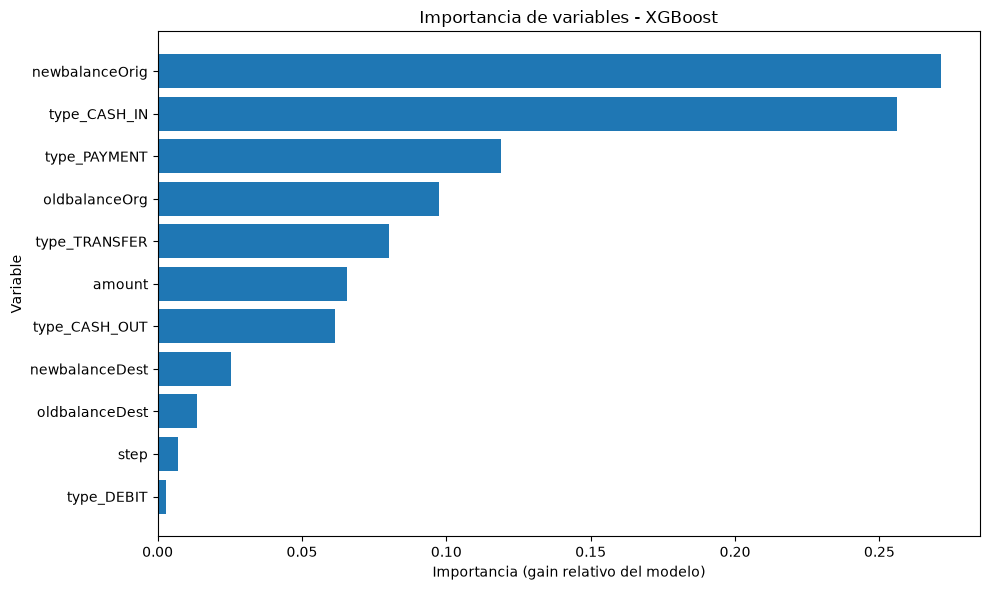

Gráfica guardada en: D:\ML_III\reports\importancia_variables.png


In [3]:
# 6. Graficar importancia de variables
importancias_plot = importancias.sort_values("importancia")

plt.figure(figsize=(10, 6))

plt.barh(
    importancias_plot["variable"],
    importancias_plot["importancia"]
)

plt.xlabel("Importancia (gain relativo del modelo)")
plt.ylabel("Variable")
plt.title("Importancia de variables - XGBoost")
plt.tight_layout()

# Guardar gráfica
RUTA_GRAFICA = RUTA_REPORTES / "importancia_variables.png"
plt.savefig(RUTA_GRAFICA, dpi=300, bbox_inches="tight")
plt.show()

print("Gráfica guardada en:", RUTA_GRAFICA.resolve())